# Variable selection
Input: X_train/X_test numerici (dummy e conteggi), y binaria (1 = Fatal+Serious).
La selezione usa il ranking per importanza di una Random Forest, ricalcolato dentro ogni fold,
e sceglie il numero di variabili con la regola 1-SE sull'ASE (Average Squared Error)
in cross-validation a 5 fold. Si usa solo il training.

## Import e configurazione

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.metrics import mean_squared_error as score
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

/opt/miniconda3/envs/ml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ID_DTYPE = {"collision_index": str}

X_train = pd.read_csv("../00_Data/Input/X_train.csv", dtype=ID_DTYPE)
X_test  = pd.read_csv("../00_Data/Input/X_test.csv",  dtype=ID_DTYPE)
y_train = pd.read_csv("../00_Data/Input/y_train.csv", dtype=ID_DTYPE)
y_test  = pd.read_csv("../00_Data/Input/y_test.csv",  dtype=ID_DTYPE)

In [3]:
RS = 42

## Preparazione dati

In [4]:
ID = "collision_index"
X_train, X_test = X_train.set_index(ID), X_test.set_index(ID)
y_train, y_test = y_train.set_index(ID), y_test.set_index(ID)

# stesse righe nello stesso ordine tra X e y
assert (X_train.index == y_train.index).all(), "X_train e y_train non allineati"
assert (X_test.index == y_test.index).all(), "X_test e y_test non allineati"

non_num = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()
print("Colonne non numeriche escluse:", non_num)

print("ID unici nel train:", X_train.index.is_unique)
print("Collisioni presenti sia in train che in test:",
      len(X_train.index.intersection(X_test.index)))

X_tr = X_train.drop(columns=non_num).astype("float32").reset_index(drop=True)
X_te = X_test.drop(columns=non_num).astype("float32").reset_index(drop=True)
y_tr = y_train.squeeze("columns").astype(int).reset_index(drop=True)
y_te = y_test.squeeze("columns").astype(int).reset_index(drop=True)

assert len(X_tr) == len(y_tr) and len(X_te) == len(y_te)
assert set(y_tr.unique()) <= {0, 1}
assert list(X_tr.columns) == list(X_te.columns)

Colonne non numeriche escluse: []
ID unici nel train: True
Collisioni presenti sia in train che in test: 0


,train_n,train_%,test_n,test_%
collision_severity_bin,,,,
0 = Slight,272433,75.76,116964,75.89
1 = Fatal/Serious,87188,24.24,37160,24.11


Rapporto Slight / KSI nel train: 3.12 : 1


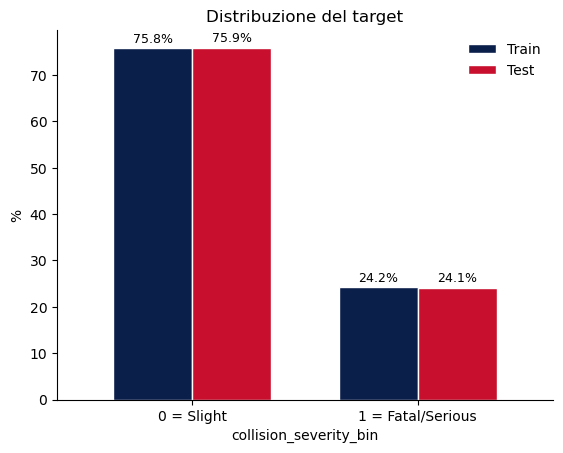

In [5]:
from pathlib import Path
Path("../02_Output_grafici").mkdir(parents=True, exist_ok=True)

NAVY, RED = "#0B1F4B", "#C8102E"

bal = pd.DataFrame({
    "train_n": y_tr.value_counts(),
    "train_%": (y_tr.value_counts(normalize=True) * 100).round(2),
    "test_n":  y_te.value_counts(),
    "test_%":  (y_te.value_counts(normalize=True) * 100).round(2),
}).rename(index={0: "0 = Slight", 1: "1 = Fatal/Serious"})

display(bal)
print(f"Rapporto Slight / KSI nel train: {bal.train_n.iloc[0] / bal.train_n.iloc[1]:.2f} : 1")

ax = bal[["train_%", "test_%"]].plot.bar(
    rot=0, ylabel="%", title="Distribuzione del target",
    color=[NAVY, RED], edgecolor="white", width=0.7
)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2, fontsize=9)
ax.legend(["Train", "Test"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig("../02_Output_grafici/03_bilanciamento_target.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
X_np, y_np = X_tr.to_numpy(), y_tr.to_numpy()

folds = list(StratifiedKFold(5, shuffle=True, random_state=RS).split(X_np, y_np))

## Ranking con Random Forest e regola 1-SE

In [7]:
p_tot = X_np.shape[1]
ns = sorted({n for n in [40, 50, 60, 70, 80] if n < p_tot} | {p_tot})

def tree_fold(tr, va, pbar):
    # ranking dentro il fold: niente leakage nella scelta di n
    Xtr, Xva, ytr, yva = X_np[tr], X_np[va], y_np[tr], y_np[va]
    rf = RandomForestClassifier(150, min_samples_leaf=50, n_jobs=-1, random_state=RS)
    rf.fit(Xtr, ytr)
    order = np.argsort(rf.feature_importances_)[::-1]
    pbar.update(1)
    out = []
    for n in ns:
        pbar.set_postfix(n=n)
        top = order[:n]
        m = RandomForestClassifier(150, min_samples_leaf=50, n_jobs=-1, random_state=RS)
        m.fit(Xtr[:, top], ytr)
        out.append(score(yva, m.predict_proba(Xva[:, top])[:, 1]))
        pbar.update(1)
    return out

total_steps = len(folds) * (1 + len(ns)) + 1
with tqdm(total=total_steps, desc="Selezione albero") as pbar:
    sc = np.array([tree_fold(tr, va, pbar) for tr, va in folds])   # (fold, n)

    tp = pd.DataFrame({"n": ns, "score_mean": sc.mean(0)})
    n_best = int(tp.loc[tp.score_mean.idxmin(), "n"])   # n con ASE minimo

    pbar.set_postfix(step="RF finale")
    rf = RandomForestClassifier(150, min_samples_leaf=50, n_jobs=-1, random_state=RS)
    rf.fit(X_np, y_np)
    order = np.argsort(rf.feature_importances_)[::-1]
    sel_tree = list(X_tr.columns[order[:n_best]])
    pbar.update(1)

print(tp.round(4).to_string(index=False), "\nn scelto (ASE minimo):", n_best)
print("Random Forest:", len(sel_tree), "variabili selezionate")

Selezione albero: 100%|██████████| 36/36 [05:41<00:00,  9.47s/it, step=RF finale]

  n  score_mean
 40      0.1578
 50      0.1578
 60      0.1580
 70      0.1579
 80      0.1582
111      0.1584 
n scelto (ASE minimo): 40
Random Forest: 40 variabili selezionate


In [8]:
best = tp.loc[tp.score_mean.idxmin()]
full = tp.loc[tp.n == p_tot].iloc[0]
print(f"Migliore in CV:       n={int(best.n):>3} | ASE {best.score_mean:.5f}")

Migliore in CV:       n= 40 | ASE 0.15782


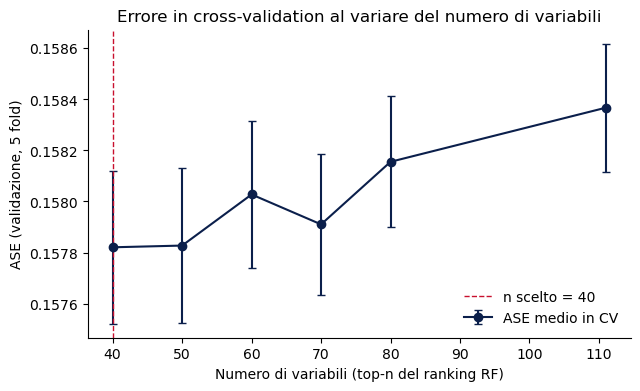

In [12]:
from pathlib import Path
Path("../02_Output_grafici").mkdir(parents=True, exist_ok=True)

se = sc.std(0, ddof=1) / np.sqrt(sc.shape[0])

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(tp.n, tp.score_mean, yerr=se, color=NAVY, marker="o", capsize=3, label="ASE medio in CV")
ax.axvline(n_best, color=RED, ls="--", lw=1, label=f"n scelto = {n_best}")
ax.set_xlabel("Numero di variabili (top-n del ranking RF)")
ax.set_ylabel("ASE (validazione, 5 fold)")
ax.set_title("Errore in cross-validation al variare del numero di variabili")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.savefig("../02_Output_grafici/03_ase_vs_n.png", dpi=300, bbox_inches="tight")
plt.show()

## Salvataggio variabili da usare

In [10]:
# Salvare le variabili selezionate per il modello finale

# variabile di controllo sul sistema di registrazione: inclusa sempre, indipendentemente dal ranking
CONTROL = ["collision_injury_based"]
# variabile temporale
TEMP_CONTROL = ["woy"]
FORCED = CONTROL + TEMP_CONTROL
sel_tree = sel_tree + [c for c in FORCED if c not in sel_tree]
print("Variabili salvate:", len(sel_tree))

# le forzate devono esistere nel dataset
missing_forced = [c for c in FORCED if c not in sel_tree]
assert not missing_forced, f"Variabili forzate assenti nel dataset: {missing_forced}"

pd.Series(sel_tree).to_csv("../00_Data/Output/selected_features.csv", index=False)

Variabili salvate: 40


In [11]:
for i in sel_tree:
    print(i)

casualty_type_Car
vehicle_type_Motorcycle over 125cc
latitude
age_of_casualty_mean
longitude
number_of_vehicles
number_of_casualties
first_point_of_impact_Back
vehicle_location_restricted_lane_Main carriageway
speed_limit
vehicle_manoeuvre_Going ahead
skidding_and_overturning_None
casualty_class_Driver or rider
collision_injury_based
first_point_of_impact_Front
urban_or_rural_area_Urban
woy
sex_of_driver_Male
casualty_class_Pedestrian
vehicle_type_Pedal cycle
vehicle_manoeuvre_Waiting or slowing
vehicle_type_Motorcycle up to 125cc
vehicle_leaving_carriageway_Nearside
junction_location_Not at junction
casualty_class_Passenger
first_point_of_impact_Side
skidding_and_overturning_Overturned
sex_of_driver_Female
pedestrian_movement_Crossing
vehicle_leaving_carriageway_Offside
road_type_Single carriageway
light_conditions_Darkness - lights lit
hit_object_off_carriageway_Tree
vehicle_manoeuvre_Turning
light_conditions_Darkness - no or unlit lighting
road_class_name_Main road
casualty_type_Van